In [2]:
import pandas as pd

ruta = "../data/raw/"

patients = pd.read_csv(ruta + "patients.csv")
encounters = pd.read_csv(ruta + "encounters.csv")
procedures = pd.read_csv(ruta + "procedures.csv")
payers = pd.read_csv(ruta + "payers.csv")
organizations = pd.read_csv(ruta + "organizations.csv")

print("patients:", patients.shape)
print("encounters:", encounters.shape)
print("procedures:", procedures.shape)
print("payers:", payers.shape)
print("organizations:", organizations.shape)




patients: (974, 20)
encounters: (27891, 14)
procedures: (47701, 9)
payers: (10, 7)
organizations: (1, 8)


In [3]:
fecha_fin = patients["DEATHDATE"].fillna(fecha_referencia)

patients["EDAD"] = (fecha_fin - patients["BIRTHDATE"]).dt.days // 365
patients["EDAD"].describe()

NameError: name 'fecha_referencia' is not defined

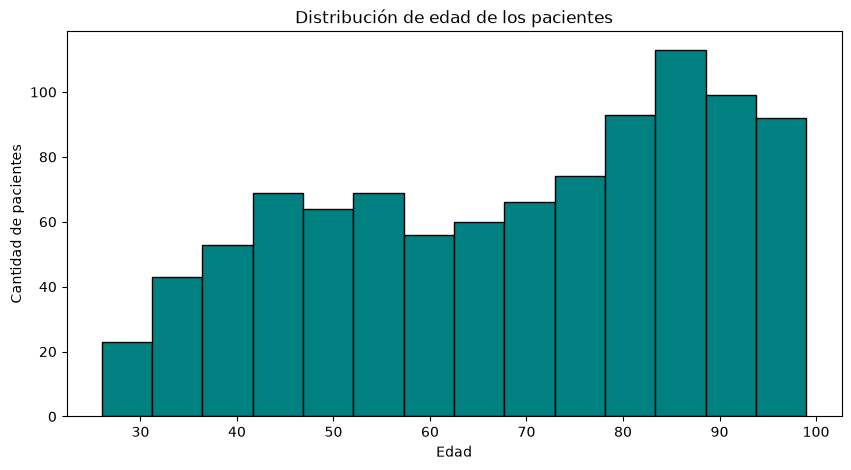

RANGO_EDAD
Menos de 40    108
40 a 59        241
60 a 79        262
80 o más       363
Name: count, dtype: int64

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(patients["EDAD"], bins=14, edgecolor="black", color="teal")
plt.title("Distribución de edad de los pacientes")
plt.xlabel("Edad")
plt.ylabel("Cantidad de pacientes")
plt.show()

patients["RANGO_EDAD"] = pd.cut(
    patients["EDAD"],
    bins=[0, 40, 60, 80, 120],
    labels=["Menos de 40", "40 a 59", "60 a 79", "80 o más"]
)

patients["RANGO_EDAD"].value_counts().sort_index()

In [ ]:
encounters.isna().sum()

Id                         0
START                      0
STOP                       0
PATIENT                    0
ORGANIZATION               0
PAYER                      0
ENCOUNTERCLASS             0
CODE                       0
DESCRIPTION                0
BASE_ENCOUNTER_COST        0
TOTAL_CLAIM_COST           0
PAYER_COVERAGE             0
REASONCODE             19541
REASONDESCRIPTION      19541
dtype: int64

In [ ]:
encounters["START"] = pd.to_datetime(encounters["START"]).dt.tz_localize(None)
encounters["STOP"] = pd.to_datetime(encounters["STOP"]).dt.tz_localize(None)

encounters[["START", "STOP"]].dtypes


encounters["AÑO"] = encounters["START"].dt.year
encounters["DURACION_HORAS"] = (encounters["STOP"] - encounters["START"]).dt.total_seconds() / 3600
encounters["PAGA_PACIENTE"] = encounters["TOTAL_CLAIM_COST"] - encounters["PAYER_COVERAGE"]

encounters[["AÑO", "DURACION_HORAS", "TOTAL_CLAIM_COST", "PAYER_COVERAGE", "PAGA_PACIENTE"]].head()
encounters["ENCOUNTERCLASS"].value_counts()


encounters[["TOTAL_CLAIM_COST", "PAYER_COVERAGE", "PAGA_PACIENTE", "DURACION_HORAS"]].describe()

,TOTAL_CLAIM_COST,PAYER_COVERAGE,PAGA_PACIENTE,DURACION_HORAS
count,27891.000000,27891.000000,27891.000000,27891.000000
mean,3639.682174,1114.965652,2524.716523,7.265995
std,9205.595748,4768.615576,7661.005002,398.323624
min,0.000000,0.000000,0.000000,0.250000
25%,142.580000,0.000000,85.550000,0.250000
50%,278.580000,28.440000,172.590000,0.250000
75%,1412.530000,155.770000,1004.630000,0.864167
max,641882.700000,247751.420000,641882.700000,44930.000000


In [8]:










sin_cobertura = encounters["PAYER_COVERAGE"] == 0

print("Consultas sin cobertura:", sin_cobertura.sum())
print("Porcentaje sin cobertura:", round(sin_cobertura.mean() * 100, 1), "%")

total_costo = encounters["TOTAL_CLAIM_COST"].sum()
total_cubierto = encounters["PAYER_COVERAGE"].sum()
print("Porcentaje del costo que cubren los seguros:", round(total_cubierto / total_costo * 100, 1), "%")
print("Porcentaje del costo que paga el paciente:", round((total_costo - total_cubierto) / total_costo * 100, 1), "%")











consultas_con_seguro = encounters.merge(
    payers[["Id", "NAME"]],
    left_on="PAYER",
    right_on="Id",
    how="left",
    suffixes=("", "_payer")
)

print(encounters.shape)
print(consultas_con_seguro.shape)







por_aseguradora = consultas_con_seguro.groupby("NAME").agg(
    consultas=("Id", "count"),
    costo_total=("TOTAL_CLAIM_COST", "sum"),
    cubierto=("PAYER_COVERAGE", "sum")
).reset_index()

por_aseguradora["%_cubierto"] = round(por_aseguradora["cubierto"] / por_aseguradora["costo_total"] * 100, 1)

por_aseguradora.sort_values("consultas", ascending=False)


Consultas sin cobertura: 13586
Porcentaje sin cobertura: 48.7 %
Porcentaje del costo que cubren los seguros: 30.6 %
Porcentaje del costo que paga el paciente: 69.4 %
(27891, 17)
(27891, 19)


,NAME,consultas,costo_total,cubierto,%_cubierto
7,Medicare,11371,24647228.89,19215691.37,78.0
8,NO_INSURANCE,8807,49259290.16,0.00,0.0
6,Medicaid,1443,8954131.02,8417973.72,94.0
5,Humana,1084,3543921.36,1953.86,0.1
0,Aetna,936,2589956.10,1780.16,0.1
2,Blue Cross Blue Shield,925,3002166.01,2074496.34,69.1
4,Dual Eligible,912,1546925.99,1380705.87,89.3
9,UnitedHealthcare,900,2563507.98,3937.32,0.2
3,Cigna Health,809,2424532.96,968.35,0.0
1,Anthem,704,2982715.05,0.00,0.0


In [14]:
por_año = encounters.groupby("AÑO").agg(
    consultas=("Id", "count"),
    pacientes=("PATIENT", "nunique"),
    costo_total=("TOTAL_CLAIM_COST", "sum"),
    costo_promedio=("TOTAL_CLAIM_COST", "mean")
).reset_index()

por_año



años_a_comparar = encounters[encounters["AÑO"].isin([2016, 2014, 2021])]

años_a_comparar.groupby(["AÑO", "ENCOUNTERCLASS"]).size().unstack()



encounters[encounters["AÑO"] == 2021]["DESCRIPTION"].value_counts().head(10)





DESCRIPTION
Administration of vaccine to produce active immunity (procedure)    1001
Encounter for problem (procedure)                                    494
Urgent care clinic (procedure)                                       375
Telemedicine consultation with patient                               338
Encounter for check up (procedure)                                   253
Emergency Encounter                                                  158
Encounter for symptom                                                151
General examination of patient (procedure)                           149
Follow-up encounter                                                  132
Encounter for 'check-up'                                              70
Name: count, dtype: int64

In [ ]:
procedures.duplicated().sum()

np.int64(0)

In [ ]:
payers.duplicated().sum()

np.int64(0)